# BÀI THỰC HÀNH 1 - BÀI 5a (TRANG 45)
## MÔN: KHAI PHÁ DỮ LIỆU
**Họ và tên:** Nguyễn Văn Hưng  
**MSSV:** 6451071029  
**Lớp:** CNTT.k64  
**Tập dữ liệu:** Online Retail Dataset (`Online Retail.xlsx`)  
**Yêu cầu:** Khai phá luật kết hợp cho thị trường Nước Đức ('Germany') với `min_sup = 5%` và `min_conf = 50%`


In [1]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# Khởi tạo các thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Các thư viện đã được nạp thành công!")


Nguyễn Văn Hưng - 6451071029
Các thư viện đã được nạp thành công!


### Bước 1: Lọc dữ liệu hóa đơn từ Nước Đức 'Germany' và gom nhóm giỏ hàng
- Đọc file `Online Retail.xlsx`, làm sạch `Description` và lọc bỏ hóa đơn tín dụng `'C'`.
- Lọc riêng các hóa đơn từ nước Đức (`Country == 'Germany'`).
- Gom nhóm `Quantity` theo `InvoiceNo` và `Description`.


In [2]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 1. Đọc và lọc hóa đơn nước Đức
df = pd.read_excel('Online Retail.xlsx')
df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# Gom nhóm giỏ hàng Germany
basket_germany = (df[df['Country'] == "Germany"]
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

print("Kích thước ma trận giỏ hàng thị trường Đức (Germany):", basket_germany.shape)
display(basket_germany.head())


Nguyễn Văn Hưng - 6451071029
Kích thước ma trận giỏ hàng thị trường Đức (Germany): (457, 1695)
Description  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  12 IVORY ROSE PEG PLACE SETTINGS  12 MESSAGE CARDS WITH ENVELOPES  12 PENCIL SMALL TUBE WOODLAND  12 PENCILS SMALL TUBE RED RETROSPOT  12 PENCILS SMALL TUBE SKULL  12 PENCILS TALL TUBE POSY  12 PENCILS TALL TUBE RED RETROSPOT  12 PENCILS TALL TUBE SKULLS  12 PENCILS TALL TUBE WOODLAND  12 PINK HEN+CHICKS IN BASKET  12 RED ROSE PEG PLACE SETTINGS  16 PIECE CUTLERY SET PANTRY DESIGN  2 PICTURE BOOK EGGS EASTER BUNNY  2 PICTURE BOOK EGGS EASTER CHICKS  20 DOLLY PEGS RETROSPOT  200 BENDY SKULL STRAWS  200 RED + WHITE BENDY STRAWS  3 DRAWER ANTIQUE WHITE WOOD CABINET  3 HOOK HANGER MAGIC GARDEN  3 HOOK PHOTO SHELF ANTIQUE WHITE  3 PIECE SPACEBOY COOKIE CUTTER SET  3 RAFFIA RIBBONS 50'S CHRISTMAS  3 STRIPEY MICE FELTCRAFT  3 TIER CAKE TIN GREEN AND CREAM  3 TIER CAKE TIN RED AND CREAM  3 TIER SWEETHEART GARDEN SHELF  3 TRADITIONAl BIS

### Bước 2: Chuyển đổi sang One-Hot Encoding và loại bỏ cước phí 'POSTAGE'
- Viết hàm chuyển đổi số lượng $\ge 1$ thành 1, $\le 0$ thành 0.
- Loại bỏ cột `'POSTAGE'` khỏi giỏ hàng.


In [3]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 2. One-hot encoding và xóa POSTAGE
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

basket_germany = basket_germany.map(encode_units)

if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)
    print("Đã loại bỏ cột 'POSTAGE' thành công!")

print("Kích thước ma trận sau khi mã hóa One-hot và bỏ POSTAGE:", basket_germany.shape)
display(basket_germany.iloc[:5, :8])


Nguyễn Văn Hưng - 6451071029
Đã loại bỏ cột 'POSTAGE' thành công!
Kích thước ma trận sau khi mã hóa One-hot và bỏ POSTAGE: (457, 1694)
Description  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  12 IVORY ROSE PEG PLACE SETTINGS  12 MESSAGE CARDS WITH ENVELOPES  12 PENCIL SMALL TUBE WOODLAND  12 PENCILS SMALL TUBE RED RETROSPOT  12 PENCILS SMALL TUBE SKULL  12 PENCILS TALL TUBE POSY
InvoiceNo                                                                                                                                                                                                                                                     
536527                            0                           0                                 0                                0                              0                                    0                            0                          0
536840                            0                           0                                 0   

### Bước 3: Tìm tập phổ biến bằng thuật toán Apriori với min_sup = 5%
- Thiết lập ngưỡng `min_support = 0.05` theo yêu cầu bài 5a.
- Hiển thị danh sách các tập phổ biến tìm được sắp xếp theo `support` giảm dần.


In [4]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 3. Tìm tập phổ biến với min_sup = 5%
frequent_itemsets_de = apriori(basket_germany.astype(bool), min_support=0.05, use_colnames=True)
frequent_itemsets_de = frequent_itemsets_de.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Tìm thấy tổng cộng {len(frequent_itemsets_de)} tập phổ biến cho thị trường Đức (min_sup = 5%):")
display(frequent_itemsets_de.head(10))


Nguyễn Văn Hưng - 6451071029
Tìm thấy tổng cộng 59 tập phổ biến cho thị trường Đức (min_sup = 5%):
    support                                           itemsets
0  0.245077    frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
1  0.157549     frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
2  0.137856      frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
3  0.137856              frozenset({REGENCY CAKESTAND 3 TIER})
4  0.131291  frozenset({ROUND SNACK BOXES SET OF 4 FRUITS, ...
5  0.126915                frozenset({WOODLAND CHARLOTTE BAG})
6  0.115974         frozenset({PLASTERS IN TIN CIRCUS PARADE})
7  0.107221              frozenset({PLASTERS IN TIN SPACEBOY})
8  0.102845                frozenset({6 RIBBONS RUSTIC CHARM})
9  0.102845                    frozenset({SPACEBOY LUNCH BOX})


### Bước 4: Tạo luật kết hợp với min_conf = 50% và trực quan hóa
- Sinh các luật kết hợp với ngưỡng độ tin cậy `min_threshold = 0.5`.
- In danh sách các luật kèm các chỉ số Support, Confidence, Lift.
- Biểu diễn độ tin cậy và độ hỗ trợ lên đồ thị phân tán (Scatter Plot).


Nguyễn Văn Hưng - 6451071029
Tổng số luật kết hợp tìm được cho thị trường Đức: 8

Danh sách các luật kết hợp:
ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ Support: 0.1313, Confidence: 0.8333, Lift: 3.4003 ]
ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [ Support: 0.1313, Confidence: 0.5357, Lift: 3.4003 ]
PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ Support: 0.0744, Confidence: 0.5397, Lift: 2.2021 ]
SPACEBOY LUNCH BOX ==> ROUND SNACK BOXES SET OF4 WOODLAND [ Support: 0.0700, Confidence: 0.6809, Lift: 2.7781 ]
PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [ Support: 0.0678, Confidence: 0.5849, Lift: 4.2429 ]
WOODLAND CHARLOTTE BAG ==> ROUND SNACK BOXES SET OF4 WOODLAND [ Support: 0.0635, Confidence: 0.5000, Lift: 2.0402 ]
PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [ Support: 0.0613, Confidence: 0.5714, Lift: 4.1451 ]
RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHAR

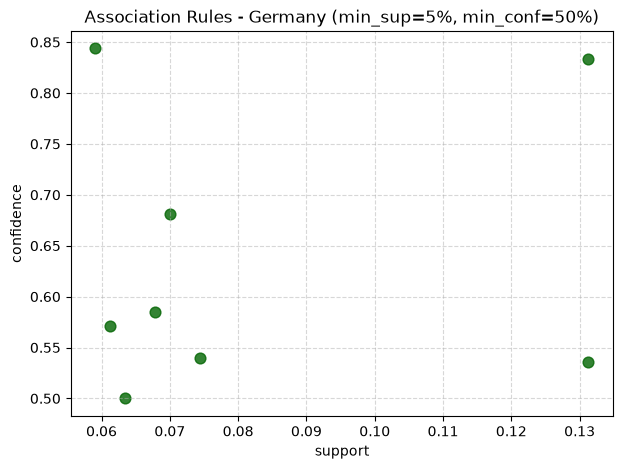

In [5]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 4. Sinh luật kết hợp với min_conf = 50%
rules_de = association_rules(frequent_itemsets_de, metric="confidence", min_threshold=0.5)

rules_de_display = rules_de.copy()
rules_de_display["antecedents"] = rules_de_display["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_de_display["consequents"] = rules_de_display["consequents"].apply(lambda x: ', '.join(list(x)))

print(f"Tổng số luật kết hợp tìm được cho thị trường Đức: {len(rules_de)}")
print("\nDanh sách các luật kết hợp:")
for i in range(len(rules_de_display)):
    row = rules_de_display.iloc[i]
    print(f"{row['antecedents']} ==> {row['consequents']} [ Support: {row['support']:.4f}, Confidence: {row['confidence']:.4f}, Lift: {row['lift']:.4f} ]")

# Biểu đồ phân tán Scatter Plot
plt.figure(figsize=(7, 5))
plt.title('Association Rules - Germany (min_sup=5%, min_conf=50%)')
plt.xlabel('Support')
plt.ylabel('Confidence')
sns.regplot(x=rules_de['support'], y=rules_de['confidence'], fit_reg=False, scatter_kws={'color': 'darkgreen', 's': 60})
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("""
Nhận xét:
- Với thị trường Đức, các sản phẩm hộp đựng đồ chơi/thức ăn trẻ em (Round Snack Boxes Set of 4 Woodland) và các loại túi ăn trưa (Lunch Bag) có mối liên hệ rất chặt chẽ.
- Tất cả các luật tìm được đều có chỉ số Lift > 1 (nhiều luật có Lift > 3.0), chứng minh sự kết hợp giữa các sản phẩm là thực sự có ý nghĩa và thúc đẩy doanh thu chéo tốt tại thị trường Đức.""")
